<a href="https://colab.research.google.com/github/muneeb0065/Deep-Learning/blob/main/Perceptron_Trick_with_Hinge_Loss.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [152]:
from sklearn.datasets import make_classification
import numpy as np

# Generate a random dataset.
X, y = make_classification(n_samples=200, n_features=2, n_informative=1,n_redundant=0,
                           n_classes=2, n_clusters_per_class=1, random_state=41,hypercube=False,class_sep=10)

In [153]:
X.shape

(200, 2)

In [154]:
y.shape


(200,)

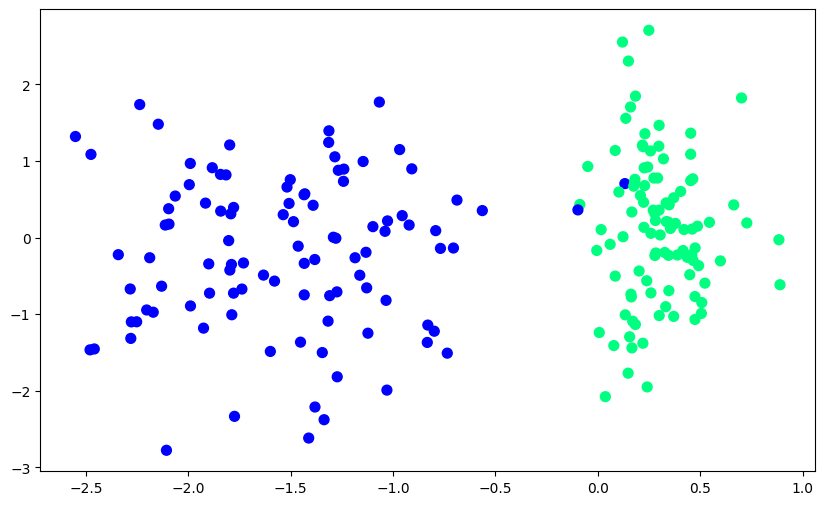

In [155]:
# Plot our data
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.scatter(X[:,0], X[:, 1] ,c=y , cmap='winter' , s=50)
# plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)

In [166]:
class perceptron:

    def __init__(self, lr=0.1, epochs = 1000):
      self.lr = lr
      self.epochs = epochs

    def fit(self, X, y):
      self.X = X
      self.y = np.where(y == 0, -1, 1) # Convert 0 labels to -1 so hinge loss works properly
      # Initialized the weights with 1
      self.w1 = 0
      self.w2 = 0
      self.b = 0

      for j in range(self.epochs):

          for i in range(self.X.shape[0]):

              # check condition
              z = self.w1*self.X[i][0] + self.w2*self.X[i][1] + self.b

              if z*self.y[i] <= 0:
                # Here we have implemented the gradient descent and updates the weights.
                  self.w1 = self.w1 + self.lr*self.y[i]*self.X[i][0]
                  self.w2 = self.w2 + self.lr*self.y[i]*self.X[i][1]
                  self.b = self.b + self.lr*self.y[i]

      # print(self.w1,self.w2,self.b)
      return self.w1,self.w2,self.b


In [167]:
X[0][0]

np.float64(0.46129481209757595)

In [168]:
percep = perceptron(epochs = 100)

In [169]:
w1,w2,b = percep.fit(X,y)
print(w1,w2,b)

1.3407211220000834 -0.012325276584081231 0.1


In [165]:
# This is Sciket learn perceptron
from sklearn.linear_model import Perceptron
percep_sklearn = Perceptron()
percep_sklearn.fit(X,y)

print(percep_sklearn.coef_)
print(percep_sklearn.intercept_)


[[ 6.24065342 -0.50005706]]
[3.]


In [160]:
m = -(w1/w2)
c = -(b/w2)

print(m,c)

-132.0286127766725 -9.77094705529262


(-3.0, 2.0)

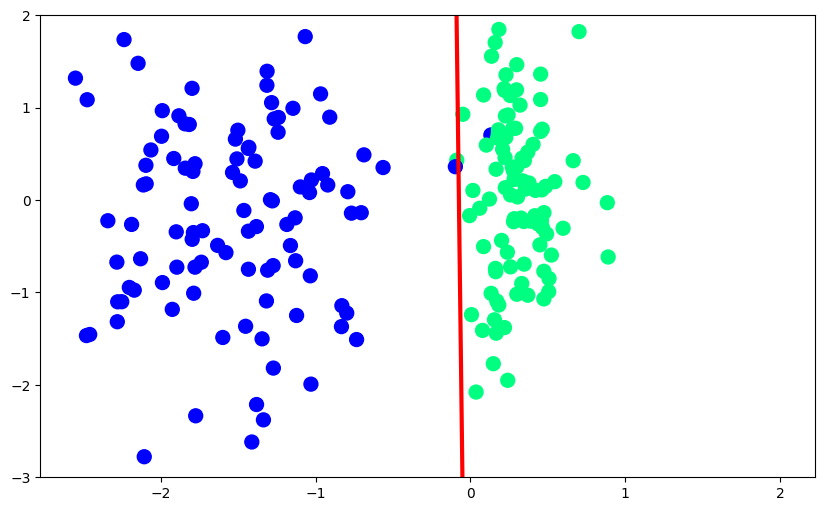

In [162]:
x_input = np.linspace(-2,2,100)
y_input = m*x_input + c

plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)